# Assignment 3: Clustering, SVM, and PCA

This assignment has **100 marks (10% of final grades)**.


**Deadline: November 23 at 11:59PM**


We will cover a variety of lectures and tutorials in this assignment, including PCA, Experimental Setup, K-Means, SVM and Multiclass Classification.

Please note that similar codes between individuals will considered violation under the academic integrity policy, and the instructor holds the right to take any necessarry action.

## Note
* Use Google Colab to do this assignment.
* Don't change existing code or text. You can modify some part of the given code by copying them to another array but the main thing is to answer the question with the exact given we give.
* Add code and write text as instructed.
* Please pay attention to questions asked after writing code to analyze or conclude results (I usually put them in bullet points and bold them)

## Submission
* File > Download > (as .ipynb)
* Submit .ipynb file on the Learn.
* Please submit by the deadline


# Question 1 - Applying PCA, and SVM (75 points)



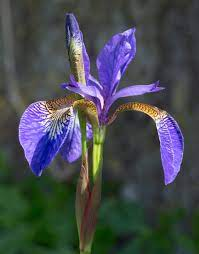


**IRIS Dataset:** The dataset consists of 50 samples from each of three species of Iris (Iris setosa, Iris virginica and Iris versicolor). Four features were measured from each sample: the length and the width of the sepals and petals, in centimeters. Based on the combination of these four features, we can develop a linear discriminant model to distinguish the species from each other.
https://en.wikipedia.org/wiki/Iris_flower_data_set

**This time you will use all 4 feature vectors (length and width features of the sepal and petal) for the all 3 flower classes and apply multiclass SVM in parts 5 and 6**


In [ ]:
import numpy as np
import pandas as pd
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pickle

In [ ]:
iris = datasets.load_iris()
print(iris.DESCR)


## Adding some noise to make it more challenging (No marks)
Creating a pandas dataframe from the observations.



In [ ]:
I=np.random.normal(1, 0.2, size=(4, 150))# Adding noise
for i in range(4):
  iris.data[:,i]=np.random.normal(1,0.2)*iris.data[:,i]*I[i,:]

Features = pd.DataFrame(iris.data, columns=iris.feature_names)
Target = pd.DataFrame(iris.target, columns=['Target'])

df = Features
df

## Securing the test data - Take 25% of data as the test data (No marks)

In [ ]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.25)
test

## Part 1 - Pre-procesing on train data (10 marks)

Apply pre-processing to your train data and save it as a new variable (StandTrain) for comparing the the effects of pre-processing **(5 mark)**.

In [ ]:
DataMean=  #write your code to calculate train set mean
DataStd=  #write your code to calculate train set std
StandTrain=  #write your code to standardize the train data

Stand_df = StandTrain.join(Target)
NonStand_df=train.join(Target)
StandTrain.mean()

Select two optional feature vectors and plot data points to make sure you have done pre-processing correctly.

Compare your results with python library results. Are they almost same? **(2 mark)**

**WRITE YOUR ANSWER HERE**



Plot two arbitary features **(3 mark)**:



In [ ]:
plt.plot(StandTrain[# write your code here
from sklearn import preprocessing
scaler = preprocessing.StandardScaler().fit(train)
X=scaler.transform(train)
plt.plot(X[:# write your code here

## Part 2 - Apply PCA and find the two most important features out of the four **(15 points)**


Now apply PCA then visualize the outcome on the standardized versions from last part. Finally compare the PCA algorithm to the python library built in PCA **(13 marks)**

In [ ]:
from scipy import linalg

def PCA(Data, Target): #num_of_features=2
# see lecture 5 and tutorial 5

  return Y


# write your code to apply pca and Plot the most important features
Y2=PCA(Stand_df[Stand_df.columns.drop('Target')])
plt.scatter(.....

# write the PCA code using python library and Plot the most important features
Y2_Python=......

Compare your PCA code vs the python library PCA code. Write your answer here in 1 sentence **(2 marks)**:

**WRITE ANSWER HERE**

##Part 3 - Apply your PCA implementation to non standardized *data* (5 marks)

In [ ]:
Y4=PCA(NonStand_df # write your code here
print(Y2.shape)
# Plot the 2 most important features
plt.scatter(.....

## Part 4 - Compare PCA (5 points)


Now compare the functionality of these methods based on the generated plots. You may apply both methods without pre-processing (NonStand_df)

# write your answer here
 (2 lines, 1 line per each experiment)
 i.e.

 1-PCA with preprocessing:


 2-PCA without preprocessing:




## Part - 5 Apply SVM on Data **(30 points)**
Now we plan to apply multiclass SVM to our data for all flower classes. We have

1.   Standardized original data
2.   Standardized reduced feature by PCA

**Use only the standardized versions for all two which makes them two in total.**

Do not forget to scale test data for standardized experiments.

**We will apply OVA (One-vs-All or One-vs-Rest) multiclass algorithm using the SGDClassifier. You can start using the svm.SVC that we used in Lecture 8 and compare it against SGDClassifier (used in Tutorial 6) but that is optional. Note that SGDClassifier uses OVA by default.**

The task is to train SVM for each one of the 2 set above using linear SVM. For the below hyperparameter combinations, first perform experiments using grid search CV and then using random search CV:

*   Apply L1 vs L2 regularization
*   Tune regularization coefficient lambda (alpha in sklearn)
*   Tune the initial learning rate
*   Apply constant learning rate vs. Decay the learning by steps


Report the test and validation accuracy for each experiment. **(24 marks, 12 marks each)**. Try to tabulate the best results for each experiment reporting the validation and testing accuracy (do NOT plot them).


To generate tables you can use the code I am providing you below and modify the way you want to present it and add as many columns and rows you need. Or you can also use this nice website to create it and save it as image to put it here: https://www.tablesgenerator.com/latex_tables

\begin{array}{ccc} \hline
Data Type & Hyperparameter Settings & Validation Accuracy & Testing Accuracy \\ \hline
Original Data & (C=1000, LR=..., Search=Grid..., etc) & 0.75 & 0.8 \\
\end{array}

In [ ]:
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV

# You will need to modify my code from Lecture 8 adn tutorial 6 to work with this dataset and use SGDClassifier to experiment over it since it has learning rate and regularization
svm = SGDClassifier(loss = 'hinge', penalty='l2', alpha=..., max_iter=1000, learning_rate=..., eta0=..., random_state = 3) # You will need to tune the LR and Regularization

# You may want to start with grid search
param_grid = {'alpha': ...., # write you code here}

grid = GridSearchCV(estimator=svm, param_grid, refit = True, verbose = 3) # you will need to play with that

grid.fit(# write your code here to fit on the standardized original data)

# Scale test data and run predictions
grid_predictions = grid.predict(# write your code here)

print(classification_report(y_test, grid_predictions)) # this is a nice built in function in sklearn please go through it and see how it reports the results

# Run 1 more grid search experiment with the standardized features of PCA

# Similarly, run random search. Define a uniform distribution to sample the values of the parameters and set n_iter = 20.
# You may need to experiment with the location and scale of the uniform distribution to obtain good results.

# Run 1 more random search experiments with the standardized features of PCA

#####################################################################     OPTIONAL        ########################################################################

# (Optional) You can compare with svm.SVC. You will need to modify my code from Lecture 8 to work with this dataset or use directly the functions in svm.SVC
svm = SVC(kernel = 'linear', C = 1, random_state = 1) # modify these your code here
svm.fit(# write your code here)

# Scale test data and and run predictions
y_pred = svm.predict(# write your code here)

print(classification_report(y_test, y_pred)) # this is a nice built in function in sklearn please go through it and see how it reports the results

Discuss the results and rank the 2 classification experiments. One or two lines about the advantage of the dimensionality reduction techniques(they may not contribute to accuracy here) (**4 points**)

**WRITE YOUR ANSWER HERE**



Report the best accuracy you have found with the hyperparameter tuning to get marks based on the ranked answers. (**2 points**)

**WRITE YOUR ANSWER HERE**

##  Part 6 - One-vs-One Multiclass SVM (OVO) **(10 marks)**

Implement the linear OVO algorithm - you can use the code I provided in the lecture. Apply it to the standardized PCA features (2-d features) and report the accuracy for the test data from OVO (do not forget to scale test data). Do not repeat the tuning from part 5 - this is just one experiment with the tuning you want to make it work the best. Compare it against the best results on PCA features from linear OVA in part 5 **(3 marks)**


In [ ]:
# Write your code here for OVO

Report the accuracy for the test data from OVO (do not forget to scale test data). Compare it against the best results on PCA features from linear OVA in part 5 **(2 marks)**

**WRITE YOUR ANSWER HERE**

Plot the fitted SVM from both linear OVO and linear OVA (like I did in Lecture 8) and compare OVO vs OVA results **(3 marks)**.

In [ ]:
# Write the plotting code here for both OVO and OVA (I already did that for you in the lecture code)

 State your observations and conlcusions about the plots in a few lines **(2 marks)**

**WRITE YOUR ANSWER HERE**



# Question 2 - Color Quantization using K-Means (25 marks)

---



In this question, you are asked to use K-Means to cluster the existing colours of the provided image into `n` clusters.




## Part 1 - Import the Image (10 marks)



The Lenna image (350, 780, 3) where 3 is the RGB channels



In [ ]:
from sklearn.datasets import load_sample_image
import PIL
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open('lenna.jpg')

img_np = np.array(img, dtype=np.uint8)
plt.imshow(img_np)
plt.axis('off')
plt.title('Image Dimension: {0},{1}'.format(img_np.shape[0], img_np.shape[1]), fontsize=20)
img = np.array(img)/255.

## Part 2 - Cluster the Image Colours using K-Means (15 marks)


Apply kmeans where the samples are the 350x780 pixels and features are the 3 RGB channels **(2 marks)**

In [ ]:
def perform_kmeans(img, n_clusters):
      """
      Write your code here
      Use Sklearn's KMeans (https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
      1) treat each pixel (3-d i.e. RGB) of the image as a data point for the KMeans algorithm

      Return: the kmeans object
      """

Now, you can use the code below to plot the clusters as a color palette and the image pixels using the cluster center values. The output should look like this:




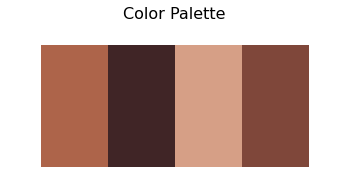

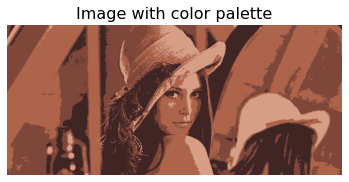


To plot the image with color palette, extract the label of each pixel and assign the cluster center value to this pixel. **(13 marks)**

Please note that each cluster center represents a RGB color.

In [ ]:
def visualize_centroids(centroids):
    fig, (ax1, ax) = plt.subplots(2, 1)
    ax1.imshow(img)
    ax1.axis('off')
    ax.axis('off')
    ax.axis([0, 0.2*len(centroids)+0.2, 0.0, 0.8])
    for i, cen in enumerate(centroids):
        p = patches.Rectangle((0.1+(i*0.2), 0.1), 0.2, 0.6,
                             facecolor=cen)
        ax.add_patch(p)

# kmns = perform_kmeans(img, n_clusters=4)
# visualize_centroids(kmns.cluster_centers_)